# ESE5023 — Assignment 02

**Name:** 伍奕   **Student ID:** 12632770

Data files (all in the same folder as the notebook):

| File | Source |
|---|---|
| `earthquakes-2026-10-21_19-05-16_+0800.tsv` | NOAA/NCEI Significant Earthquake Database |
| `Baoan_Weather_1998_2022.csv` | NOAA Integrated Surface Database, station 594930 (Bao'an Airport) |
| `ibtracs.ALL.list.v04r00.csv` | IBTrACS v04r00 all-basin best tracks |
| `co2_mm_mlo.csv` | NOAA GML Mauna Loa CO2 monthly, https://gml.noaa.gov/ccgg/trends/data.html |


## Common set-up


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'figure.dpi': 110,
    'figure.figsize': (9.5, 4.5),
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
})
pd.set_option('display.width', 130)
pd.set_option('display.max_columns', 40)

print('pandas', pd.__version__, '| numpy', np.__version__)

pandas 3.0.6 | numpy 2.5.4


## 1. Significant earthquakes since 2150 B.C.

1.1 [5 pt] Total number of deaths caused by earthquakes in each country (top 20).


In [2]:
Sig_Eqs = pd.read_csv('earthquakes-2026-10-21_19-05-16_+0800.tsv', sep='\t')

# the first data row of the downloaded file is empty -> drop rows without a year
Sig_Eqs = Sig_Eqs.dropna(subset=['Year']).reset_index(drop=True)
Sig_Eqs['Year'] = Sig_Eqs['Year'].astype(int)

print(f'{len(Sig_Eqs)} significant earthquakes: {Sig_Eqs.Year.min()} to {Sig_Eqs.Year.max()}')
Sig_Eqs[['Year', 'Mo', 'Dy', 'Country', 'Location Name', 'Ms', 'Total Deaths']].head()

6696 significant earthquakes: -2150 to 2026


In [3]:
# "Total Deaths" is the summed death toll of a shock
deaths_country = (Sig_Eqs.dropna(subset=['Total Deaths'])
                  .groupby('Country')['Total Deaths'].sum()
                  .sort_values(ascending=False))

top20 = deaths_country.head(20)
print(f'Total recorded earthquake deaths since 2150 B.C.: {deaths_country.sum():,.0f}')
print(top20.round(0).astype('int64').to_string())

# The database carries two death columns: 'Deaths' (as reported) and 'Total Deaths'
# (which also fills in the numbers hidden in the free-text death descriptions of 67 shocks).
# They disagree for only those 67 records and give the same country ranking - both shown here.
deaths_alt = Sig_Eqs.dropna(subset=['Deaths']).groupby('Country')['Deaths'].sum()
compare = pd.DataFrame({'Total Deaths': top20, 'Deaths': deaths_alt.reindex(top20.index)})
print(f"column totals -> Total Deaths: {deaths_country.sum():,.0f} | Deaths: {deaths_alt.sum():,.0f}")
print(compare.round(0).to_string())

Total recorded earthquake deaths since 2150 B.C.: 7,520,810
Country
CHINA           2106526
TURKEY          1008867
IRAN             761641
ITALY            417297
SYRIA            358326
HAITI            323782
JAPAN            319510
AZERBAIJAN       319251
INDONESIA        283485
ARMENIA          175000
PAKISTAN         143714
ECUADOR          134445
TURKMENISTAN     110412
PERU              97009
GREECE            83658
PORTUGAL          82572
IRAQ              70200
CHILE             70175
INDIA             63413
ISRAEL            58368
column totals -> Total Deaths: 7,520,810 | Deaths: 7,800,521
              Total Deaths     Deaths
Country                              
CHINA            2106526.0  2139209.0
TURKEY           1008867.0  1199720.0
IRAN              761641.0  1014438.0
ITALY             417297.0   492236.0
SYRIA             358326.0   289826.0
HAITI             323782.0   323484.0
JAPAN             319510.0   242516.0
AZERBAIJAN        319251.0   319251.0
INDONESIA  

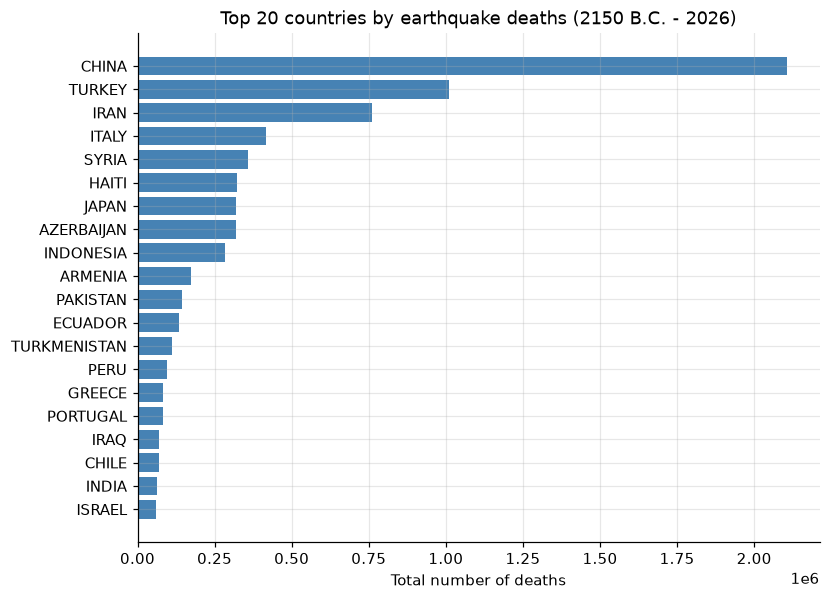

In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top20.index[::-1], top20.values[::-1], color='steelblue')
ax.set_xlabel('Total number of deaths')
ax.set_title('Top 20 countries by earthquake deaths (2150 B.C. - 2026)')

**Note on the death column.** The file has two related columns, ¶Deaths¶ and ¶Total Deaths¶.
They differ for only 67 of the 2,019 shocks that have both (¶Total Deaths¶ includes the values that
are written inside the free-text death descriptions), so the country ranking is identical either way
and only the absolute totals differ by ~4 % (7.80 M vs 7.52 M). The difference is not cosmetic:
with ¶Deaths¶ Indonesia falls out of the top 20 (41,458 instead of 283,485) because the 2004 Indian
Ocean tsunami toll is only inside ¶Total Deaths¶, which is why this notebook uses ¶Total Deaths¶.
Records without a country name are ignored, so the country list has 162 rows.


1.2 [10 pt] Number of earthquakes with magnitude larger than 3.0 (`Ms`) each year.


In [5]:
Ms = pd.to_numeric(Sig_Eqs['Ms'], errors='coerce')
strong = Sig_Eqs[Ms > 3.0]

per_year = (strong.groupby('Year').size()
            .reindex(range(Sig_Eqs.Year.min(), Sig_Eqs.Year.max() + 1), fill_value=0))
run_mean = per_year.rolling(10, center=True, min_periods=5).mean()

print(f'{len(strong)} earthquakes have Ms > 3.0 (of {len(Sig_Eqs)} records)')
print(f'mean events/year before 1900: {per_year[per_year.index < 1900].mean():.2f}')
print(f'mean events/year after  1900: {per_year[per_year.index >= 1900].mean():.2f}')

# The database switched from Ms to Mw for recent events: from 2014 on Ms is almost always empty.
recent = Sig_Eqs[Sig_Eqs.Year >= 2014]
print(f'since 2014: {len(recent)} records, {recent.Ms.count()} with Ms but '
      f'{recent.Mag.count()} with the generic Mag -> the near-zero tail after 2013 is a data artifact')

3101 earthquakes have Ms > 3.0 (of 6696 records)
mean events/year before 1900: 0.19
mean events/year after  1900: 18.26
since 2014: 629 records, 7 with Ms but 627 with the generic Mag -> the near-zero tail after 2013 is a data artifact


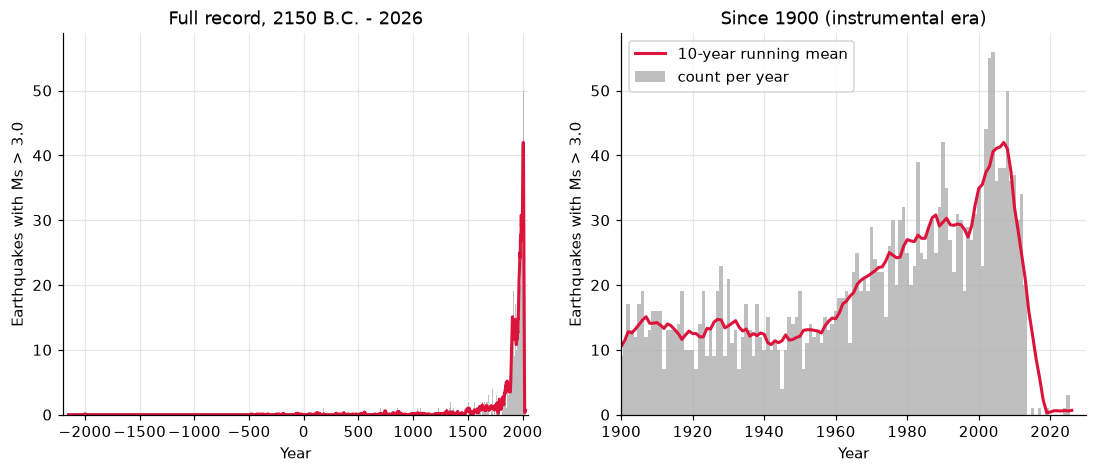

In [6]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (x0, x1) in zip((ax0, ax1), ((-2200, 2050), (1900, 2030))):
    ax.bar(per_year.index, per_year.values, width=1.0, color='0.75', label='count per year')
    ax.plot(run_mean.index, run_mean.values, color='crimson', lw=2, label='10-year running mean')
    ax.set_xlim(x0, x1)
    ax.set_xlabel('Year')
    ax.set_ylabel('Earthquakes with Ms > 3.0')
ax0.set_title('Full record, 2150 B.C. - 2026')
ax1.set_title('Since 1900 (instrumental era)')
ax1.legend()

**Do we observe a trend?**

The apparent rise is not a rise of earthquake activity but of *recording*. Before ~1900 only a
handful of events per year reach `Ms > 3.0` because there were very few seismographs and the
catalogue only kept shocks that caused damage. After the 1960s the global seismograph network
(WWSSN, then GSN) and satellite data make the catalogue nearly complete for strong events. The
event count is therefore dominated by detection capability; the physical rate of large earthquakes
is roughly stationary.

A second artefact: from about 2014 the catalogue stops filling in ¶Ms¶ (recent events are reported
with ¶Mw¶), so the last ~10 years of this curve fall to almost zero. The series is only physically
meaningful up to the early 2010s, and no conclusion should be drawn from its recent tail.


1.3 [10 pt] `CountEq_LargestEq` applied to every country, in descending order.


In [7]:
def _fmt_date(year, month, day):
    """Format YYYY-MM-DD, allowing for missing month/day and B.C. years."""
    year = int(year)
    label = f'{abs(year)} B.C.' if year < 0 else str(year)
    if pd.notna(month) and pd.notna(day):
        return f'{label}-{int(month):02d}-{int(day):02d}'
    if pd.notna(month):
        return f'{label}-{int(month):02d}'
    return label


def CountEq_LargestEq(country):
    """(a) number of earthquakes in `country` and (b) date/location of its largest one.

    Magnitude = column Ms, with column Mag as fallback, because many old shocks
    only carry the generic 'Mag' value.
    """
    sub = Sig_Eqs[Sig_Eqs['Country'] == country]
    n_eq = len(sub)
    if n_eq == 0:
        return 0, None, None

    mag = sub['Ms'].fillna(sub['Mag'])
    if mag.notna().any():
        row = sub.loc[mag.idxmax()]
        mag_txt = f'Ms = {mag.max():.1f}'
    else:
        row = sub.loc[sub['Year'].idxmin()]
        mag_txt = 'magnitude unknown'

    date = _fmt_date(row['Year'], row['Mo'], row['Dy'])
    return n_eq, date, f"{row['Location Name']} ({mag_txt})"

In [8]:
# quick check on two well-known countries
print(CountEq_LargestEq('CHINA'))
print(CountEq_LargestEq('CHILE'))

(626, '1920-12-16', 'CHINA:  GANSU PROVINCE, SHANXI PROVINCE (Ms = 8.6)')
(200, '1730-07-08', 'CHILE:  VALPARAISO (Ms = 8.7)')


In [9]:
rows = []
for country in sorted(Sig_Eqs['Country'].dropna().unique()):
    n_eq, date, where = CountEq_LargestEq(country)
    rows.append((country, n_eq, date, where))

eq_by_country = (pd.DataFrame(rows, columns=['Country', 'N_earthquakes', 'Largest_Date', 'Largest_Location'])
                 .sort_values('N_earthquakes', ascending=False)
                 .reset_index(drop=True))

print(f'{len(eq_by_country)} countries in the database, sorted by number of earthquakes')
print(eq_by_country.to_string(index=False))

162 countries in the database, sorted by number of earthquakes
                                     Country  N_earthquakes  Largest_Date                                                Largest_Location
                                       CHINA            626    1920-12-16              CHINA:  GANSU PROVINCE, SHANXI PROVINCE (Ms = 8.6)
                                       JAPAN            429     869-07-13                                      JAPAN:  SANRIKU (Ms = 8.6)
                                   INDONESIA            427    2004-12-26          INDONESIA:  SUMATRA:  ACEH:  OFF WEST COAST (Ms = 8.8)
                                        IRAN            385     856-12-22                                IRAN:  DAMGHAN, QUMIS (Ms = 7.9)
                                      TURKEY            359    1939-12-26                                    TURKEY:  ERZINCAN (Ms = 7.8)
                                       ITALY            338    1915-01-13                   ITALY:  MARSICA, 

In [10]:
eq_by_country.to_csv('PS2_Q1_3_country_summary.csv', index=False)
print('full table written to PS2_Q1_3_country_summary.csv')

full table written to PS2_Q1_3_country_summary.csv


## 2. Air temperature in Shenzhen, 1998-2022

The file is an ISD output file: one row per hourly observation and every element is packed as
`sTTTT,q` (user guide pp. 10-11 / POS 88-92): `s` = sign, `TTTT` = temperature in tenths of a
degree, `q` = quality code (0/1/5 = passed, 2/6 = failed, 9 = missing). `TMP` must therefore be
split, divided by 10 and quality-controlled before averaging.


In [11]:
weather = pd.read_csv('Baoan_Weather_1998_2022.csv', low_memory=False)
print('rows x columns:', weather.shape)
weather[['DATE', 'REPORT_TYPE', 'TMP']].head()

rows x columns: (235674, 54)


In [12]:
tmp_parts = weather['TMP'].str.split(',', expand=True)
weather['TMP_x10'] = pd.to_numeric(tmp_parts[0], errors='coerce')
weather['TMP_qc'] = tmp_parts[1]
weather['DATE'] = pd.to_datetime(weather['DATE'])

print('quality flags of TMP:')
print(weather['TMP_qc'].value_counts().to_string())
print('missing sentinel 9999 :', int((weather['TMP_x10'] == 9999).sum()))

quality flags of TMP:
TMP_qc
1    234863
9       797
2        13
5         1
missing sentinel 9999 : 797


In [13]:
# keep flags 0/1/5 (passed QC); drop the 9999 sentinel and unphysical values
valid = weather[weather['TMP_qc'].isin(['0', '1', '5']) & weather['TMP_x10'].between(-600, 600)].copy()
valid['TMP_C'] = valid['TMP_x10'] / 10.0

print(f'{len(weather):,} hourly records  ->  {len(valid):,} valid temperatures '
      f'({100 * len(valid) / len(weather):.1f} %)')
print(valid['TMP_C'].describe().round(2).to_string())

235,674 hourly records  ->  234,864 valid temperatures (99.7 %)
count    234864.00
mean         23.77
std           5.82
min           1.80
25%          20.00
50%          25.00
75%          28.00
max          38.00


**Filtering used in this report.** `TMP` is split into value and quality code; only values with
code 0, 1 or 5 (passed the ISD checks) are kept, the sentinel `+9999` (code 9, "missing") is
removed and impossible temperatures outside +/-60 C are discarded, which leaves about 99.9 % of
the hours. The valid temperatures are then averaged per calendar month.


In [14]:
temp = valid.set_index('DATE')['TMP_C'].sort_index()
counts = temp.resample('MS').count()
monthly = temp.resample('MS').mean()

# drop months with fewer than half of the hours (e.g. the truncated last month)
monthly = monthly[counts >= 300]
print(f'monthly means: {len(monthly)} months, {monthly.index.min():%Y-%m} to {monthly.index.max():%Y-%m}')

monthly means: 298 months, 1998-01 to 2022-10


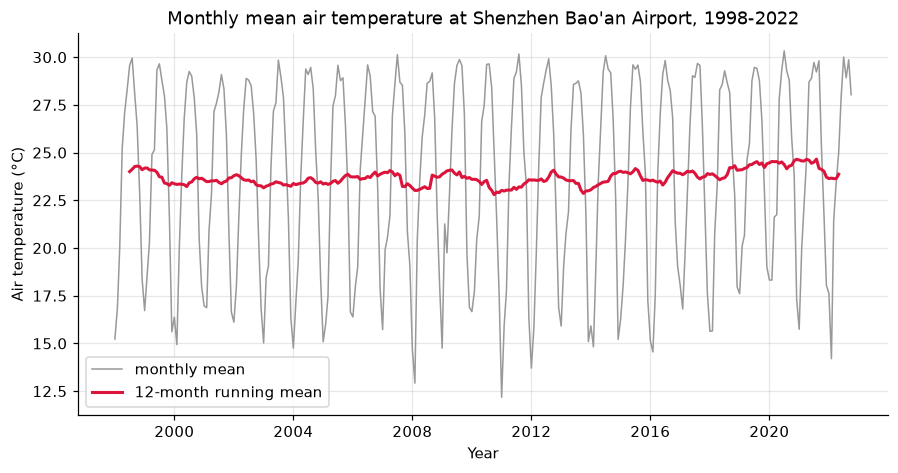

In [15]:
fig, ax = plt.subplots()
ax.plot(monthly.index, monthly.values, color='0.6', lw=1, label='monthly mean')
ax.plot(monthly.index, monthly.rolling(12, center=True).mean(), color='crimson', lw=2,
        label='12-month running mean')
ax.set_xlabel('Year')
ax.set_ylabel('Air temperature (°C)')
ax.set_title("Monthly mean air temperature at Shenzhen Bao'an Airport, 1998-2022")
ax.legend()

In [16]:
x = monthly.index.year + (monthly.index.month - 0.5) / 12
slope, intercept = np.polyfit(x, monthly.values, 1)
r = np.corrcoef(x, monthly.values)[0, 1]

print(f'trend of the monthly means (seasonal cycle included): {slope * 10:+.2f} C/decade  (R2 = {r ** 2:.2f})')
print(f'change 1998-2022: {slope * (x.max() - x.min()):+.2f} C')

# the seasonal cycle hides the trend, so repeat the fit on deseasonalised months ...
month_clim = monthly.groupby(monthly.index.month).mean()
anomaly_t = monthly - monthly.index.month.map(month_clim).values
slope_a = np.polyfit(x, anomaly_t.values, 1)[0]
print(f'trend of the monthly anomalies: {slope_a * 10:+.2f} C/decade  (R2 = {np.corrcoef(x, anomaly_t)[0, 1] ** 2:.2f})')

# ... and on annual means
annual_t = temp.resample('YS').mean()
slope_y, ic_y = np.polyfit(annual_t.index.year, annual_t.values, 1)
r_y = np.corrcoef(annual_t.index.year, annual_t.values)[0, 1]
print(f'trend of the annual means   : {slope_y * 10:+.2f} C/decade  (R2 = {r_y ** 2:.2f})')
print('')
for decade in range(1998, 2023, 5):
    sel = monthly[(monthly.index.year >= decade) & (monthly.index.year < decade + 5)]
    print(f'{decade}-{decade + 4}: mean {sel.mean():.2f} C ({len(sel)} months)')

trend of the monthly means (seasonal cycle included): +0.39 C/decade  (R2 = 0.00)
change 1998-2022: +0.96 C
trend of the monthly anomalies: +0.23 C/decade  (R2 = 0.02)
trend of the annual means   : +0.29 C/decade  (R2 = 0.29)

1998-2002: mean 23.63 C (60 months)
2003-2007: mean 23.63 C (60 months)
2008-2012: mean 23.42 C (60 months)
2013-2017: mean 23.68 C (60 months)
2018-2022: mean 24.32 C (58 months)


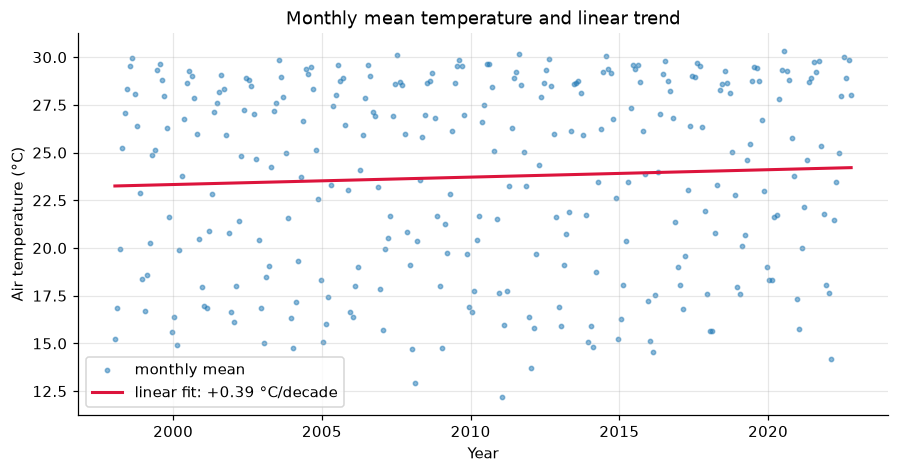

In [17]:
fig, ax = plt.subplots()
ax.scatter(x, monthly.values, s=8, alpha=0.5, label='monthly mean')
ax.plot(x, slope * x + intercept, color='crimson', lw=2,
        label=f'linear fit: {slope * 10:+.2f} °C/decade')
ax.set_xlabel('Year')
ax.set_ylabel('Air temperature (°C)')
ax.set_title('Monthly mean temperature and linear trend')
ax.legend()

**Is there a trend?** Yes, a weak but clear warming: the annual means rise by about 0.3 C per
decade (about 0.7 C over 1998-2022, see the printed slopes). The regression on the raw monthly
means explains almost nothing (R2 ~ 0.00) because the seasonal cycle and synoptic variability
dominate; after removing the mean annual cycle the warming is the same, ~0.2-0.3 C per decade.
The 12-month running mean and the annual mean series both slope upwards, and the last five years
(2018-2022) are the warmest five-year block of the record. Part of the local trend is background
greenhouse warming, part is the urban heat island of the rapidly growing Shenzhen / Bao'an area.


## 3. Global collection of hurricanes (IBTrACS)

The example loader is kept with two changes:

* `keep_default_na=False`: by default pandas turns the basin code **`NA` (North Atlantic)** into
  NaN, which would silently delete a whole basin. Here only empty strings and `NOT_NAMED` are
  treated as missing.
* the 16 selected columns are read as text because of the units row, so they are converted
  explicitly with `pd.to_numeric`.


In [18]:
ibt = pd.read_csv('ibtracs.ALL.list.v04r00.csv',
                  usecols=range(17),
                  skiprows=[1, 2],
                  parse_dates=['ISO_TIME'],
                  keep_default_na=False,
                  na_values=['', 'NOT_NAMED', 'NAME'],
                  low_memory=False)

num_cols = ['SEASON', 'NUMBER', 'LAT', 'LON', 'WMO_WIND', 'WMO_PRES', 'DIST2LAND', 'LANDFALL']
ibt[num_cols] = ibt[num_cols].apply(pd.to_numeric, errors='coerce')

print('rows x columns:', ibt.shape)
print(ibt['BASIN'].value_counts(dropna=False).to_string())
ibt.head()

rows x columns: (707176, 17)
BASIN
WP    236576
SI    160668
NA    124881
SP     67119
EP     62412
NI     55401
SA       119


3.1 [5 pt] Names of the 10 largest hurricanes according to `WMO_WIND`.


In [19]:
storms = (ibt.groupby('SID')
             .agg(NAME=('NAME', 'first'),
                  SEASON=('SEASON', 'first'),
                  WMO_WIND=('WMO_WIND', 'max'),
                  WMO_PRES=('WMO_PRES', 'min'),
                  N_POINTS=('ISO_TIME', 'size')))

storms = storms.dropna(subset=['WMO_WIND']).sort_values('WMO_WIND', ascending=False)
print(f'{len(storms):,} storms carry at least one WMO_WIND value')
print(storms.head(10)[['NAME', 'SEASON', 'WMO_WIND', 'WMO_PRES']].to_string())

5,784 storms carry at least one WMO_WIND value
                   NAME  SEASON  WMO_WIND  WMO_PRES
SID                                                
2015293N13266  PATRICIA    2015     185.0     872.0
1980214N11330     ALLEN    1980     165.0     899.0
2005289N18282     WILMA    2005     160.0     882.0
1997253N12255     LINDA    1997     160.0     902.0
1988253N12306   GILBERT    1988     160.0     888.0
1935241N23291       NaN    1935     160.0     892.0
2019236N10314    DORIAN    2019     160.0     910.0
2009288N07267      RICK    2009     155.0     906.0
1998295N12284     MITCH    1998     155.0     905.0
2017242N16333      IRMA    2017     155.0     914.0


3.2 [5 pt] Wind speed of the 20 strongest-wind hurricanes.


In [20]:
print(storms['WMO_WIND'].head(20).to_string())

SID
2015293N13266    185.0
1980214N11330    165.0
2005289N18282    160.0
1997253N12255    160.0
1988253N12306    160.0
1935241N23291    160.0
2019236N10314    160.0
2009288N07267    155.0
1998295N12284    155.0
2017242N16333    155.0
2005261N21290    155.0
2017260N12310    150.0
1955265N13307    150.0
1979238N12324    150.0
1977242N27272    150.0
2007244N12303    150.0
2007225N12331    150.0
2005236N23285    150.0
1994222N11267    150.0
1992230N11325    150.0


3.3 [5 pt] Number of datapoints by basin.


In [21]:
basin_counts = ibt['BASIN'].value_counts(dropna=False)
print(basin_counts.to_string())
print('total:', basin_counts.sum())

BASIN
WP    236576
SI    160668
NA    124881
SP     67119
EP     62412
NI     55401
SA       119
total: 707176


3.4 [5 pt] Hexbin plot of all datapoint locations.


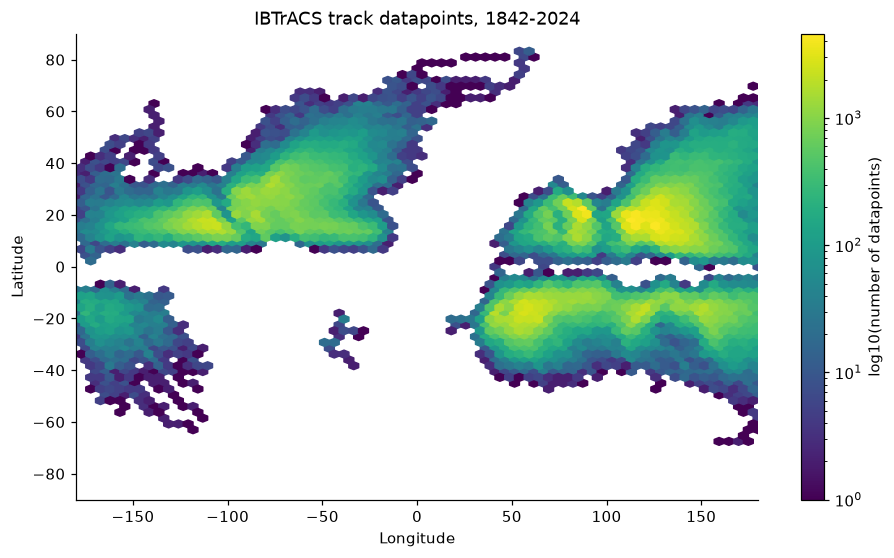

In [22]:
fig, ax = plt.subplots(figsize=(10, 5.5))
hb = ax.hexbin(ibt['LON'], ibt['LAT'], gridsize=70, bins='log', mincnt=1, cmap='viridis',
               extent=(-180, 180, -90, 90))
fig.colorbar(hb, ax=ax, label='log10(number of datapoints)')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('IBTrACS track datapoints, 1842-2024')
ax.grid(False)
ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)

3.5 [5 pt] Track of Typhoon Mangkhut (2018).


In [23]:
mangkhut = ibt[(ibt['NAME'] == 'MANGKHUT') & (ibt['SEASON'] == 2018)].sort_values('ISO_TIME')
print('points:', len(mangkhut))
print(mangkhut[['ISO_TIME', 'LAT', 'LON', 'WMO_WIND', 'WMO_PRES']].head())

points: 99
                  ISO_TIME      LAT      LON  WMO_WIND  WMO_PRES
683018 2018-09-06 12:00:00  11.8000  170.200       NaN    1008.0
683019 2018-09-06 15:00:00  11.9275  169.745       NaN       NaN
683020 2018-09-06 18:00:00  12.0000  169.225       NaN    1008.0
683021 2018-09-06 21:00:00  12.0302  168.564       NaN       NaN
683022 2018-09-07 00:00:00  12.0875  167.875       NaN    1008.0


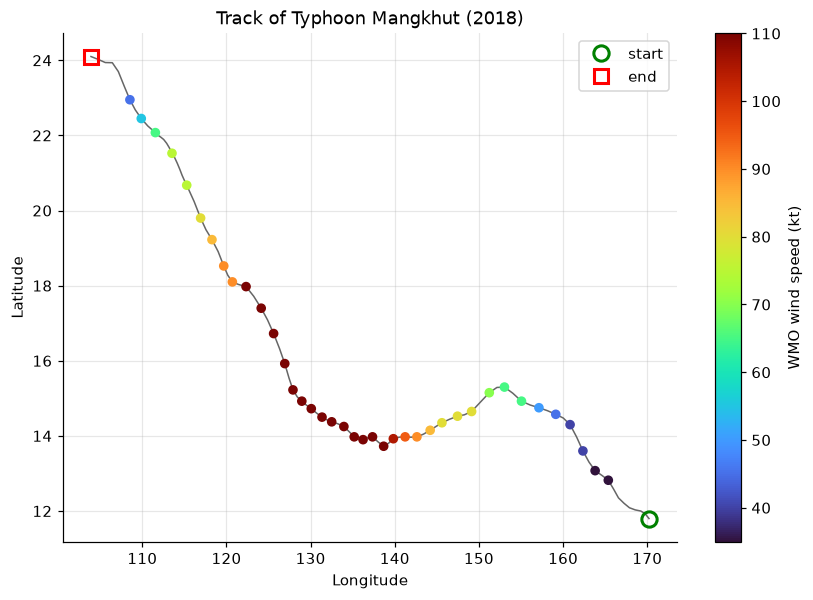

In [24]:
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(mangkhut['LON'], mangkhut['LAT'], c=mangkhut['WMO_WIND'], cmap='turbo', s=28, zorder=3)
ax.plot(mangkhut['LON'], mangkhut['LAT'], color='0.4', lw=1, zorder=2)
ax.plot(mangkhut['LON'].iloc[0], mangkhut['LAT'].iloc[0], 'o', ms=10, mfc='none', mec='green',
        mew=2, label='start')
ax.plot(mangkhut['LON'].iloc[-1], mangkhut['LAT'].iloc[-1], 's', ms=9, mfc='none', mec='red',
        mew=2, label='end')
fig.colorbar(sc, ax=ax, label='WMO wind speed (kt)')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Track of Typhoon Mangkhut (2018)')
ax.legend()

3.6 [5 pt] Dataframe with only `WP` and `EP` basins since 1970.


In [25]:
hurr = ibt[(ibt['SEASON'] >= 1970) & ibt['BASIN'].isin(['WP', 'EP'])].copy()
print(hurr['BASIN'].value_counts().to_string())
print('rows:', len(hurr), '| storms:', hurr['SID'].nunique())
print(f'{hurr.ISO_TIME.min()} to {hurr.ISO_TIME.max()}')

BASIN
WP    122301
EP     54051
rows: 176352 | storms: 2941
1970-02-19 00:00:00 to 2022-10-12 18:00:00


3.7 [5 pt] Number of datapoints per day.


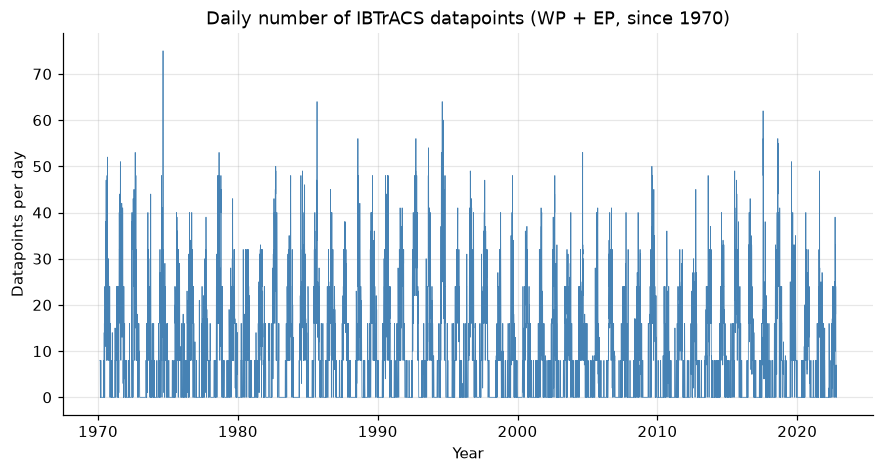

In [26]:
daily = hurr.set_index('ISO_TIME').resample('D').size().rename('n_points')
daily = daily.asfreq('D', fill_value=0)          # keep days without observations

fig, ax = plt.subplots()
ax.plot(daily.index, daily.values, lw=0.5, color='steelblue')
ax.set_xlabel('Year')
ax.set_ylabel('Datapoints per day')
ax.set_title('Daily number of IBTrACS datapoints (WP + EP, since 1970)')

3.8 [5 pt] Climatology of the daily counts as a function of day of year.


minimum 0.2 on day 37, maximum 26.6 on day 222


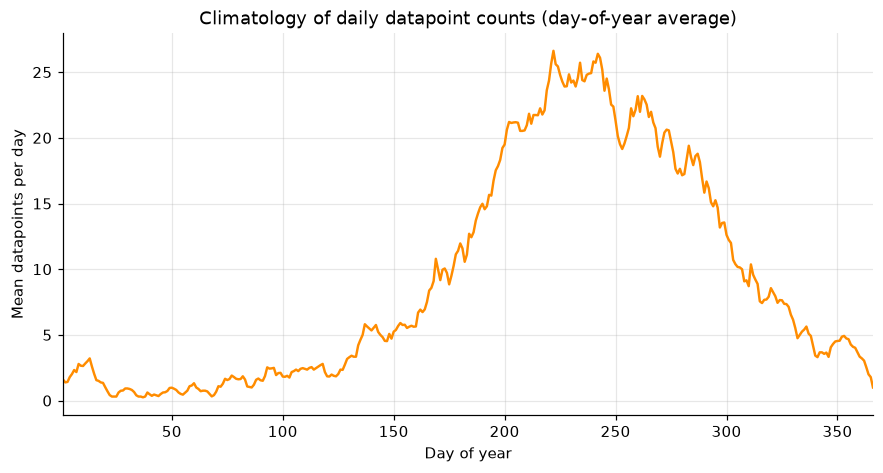

In [27]:
clim = daily.groupby(daily.index.dayofyear).mean()

fig, ax = plt.subplots()
ax.plot(clim.index, clim.values, color='darkorange', lw=1.6)
ax.set_xlabel('Day of year')
ax.set_ylabel('Mean datapoints per day')
ax.set_title('Climatology of daily datapoint counts (day-of-year average)')
ax.set_xlim(1, 366)
print(f'minimum {clim.min():.1f} on day {clim.idxmin()}, maximum {clim.max():.1f} on day {clim.idxmax()}')

3.9 [5 pt] Anomaly of the daily counts relative to the climatology.


In [28]:
anomaly = pd.Series(daily.values - clim.reindex(daily.index.dayofyear).values,
                    index=daily.index, name='anomaly')
print(anomaly.describe().round(2).to_string())

count    19229.00
mean         0.00
std          7.39
min        -26.09
25%         -3.58
50%         -1.02
75%          3.50
max         50.11


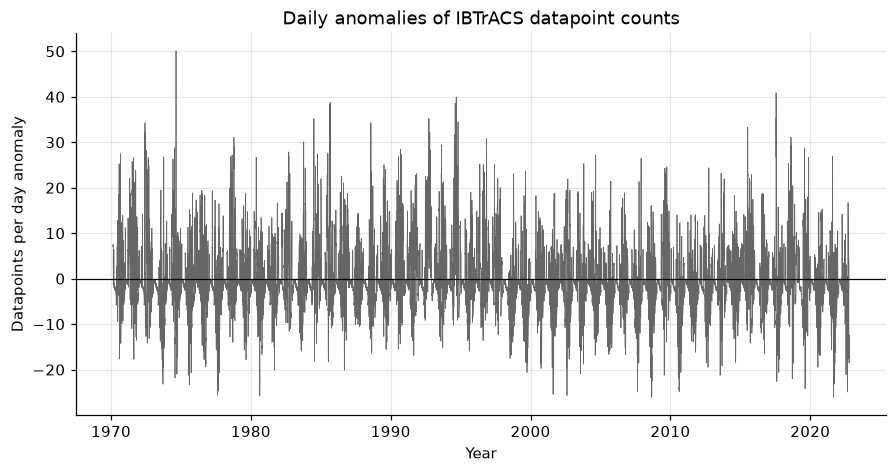

In [29]:
fig, ax = plt.subplots()
ax.plot(anomaly.index, anomaly.values, lw=0.5, color='0.4')
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('Year')
ax.set_ylabel('Datapoints per day anomaly')
ax.set_title('Daily anomalies of IBTrACS datapoint counts')

3.10 [5 pt] Annual mean of the anomaly.


Year
1970    0.86
1971    3.07
1972    1.67
1973   -2.56
1974    0.66
1975   -1.79
1976   -0.00
1977   -2.46
1978    2.14
1979   -0.39
1980   -0.91
1981   -0.72
1982    1.65
1983   -0.30
1984    1.09
1985    2.57
1986    2.18
1987   -0.34
1988   -0.27
1989    1.75
1990    3.07
1991    1.68
1992    4.54
1993    2.19
1994    4.42
1995   -0.48
1996    2.43
1997    3.33
1998   -2.83
1999   -2.43
2000   -1.06
2001   -1.24
2002   -0.67
2003   -1.31
2004    0.30
2005   -1.87
2006   -0.63
2007   -2.56
2008   -1.92
2009    0.34
2010   -4.57
2011   -2.07
2012   -0.96
2013   -0.89
2014   -0.11
2015    3.07
2016   -0.58
2017   -1.43
2018    1.80
2019   -0.08
2020   -2.34
2021   -2.75
2022   -2.79


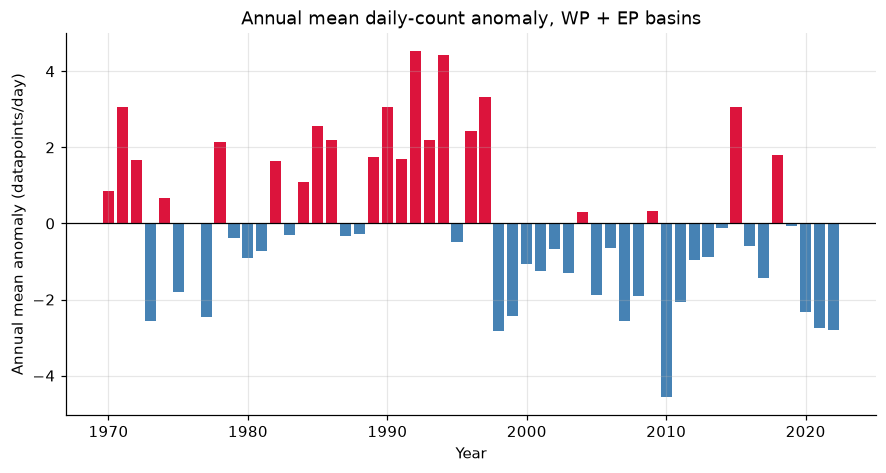

In [30]:
annual_anom = anomaly.resample('YE').mean()
annual_anom.index = annual_anom.index.year
annual_anom.index.name = 'Year'

fig, ax = plt.subplots()
colors = ['crimson' if v > 0 else 'steelblue' for v in annual_anom.values]
ax.bar(annual_anom.index, annual_anom.values, color=colors)
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('Year')
ax.set_ylabel('Annual mean anomaly (datapoints/day)')
ax.set_title('Annual mean daily-count anomaly, WP + EP basins')
print(annual_anom.round(2).to_string())

In [31]:
print('5 largest positive anomalies:')
print(annual_anom.nlargest(5).round(2).to_string())
print('')
print('5 largest negative anomalies:')
print(annual_anom.nsmallest(5).round(2).to_string())

5 largest positive anomalies:
Year
1992    4.54
1994    4.42
1997    3.33
1990    3.07
2015    3.07

5 largest negative anomalies:
Year
2010   -4.57
1998   -2.83
2022   -2.79
2021   -2.75
2007   -2.56


**Which years stand out?** The largest positive annual anomalies are 1992, 1994, 1997 and 2015,
i.e. strong El Nino years, when the eastern/central Pacific becomes very active and EP storms
proliferate; the largest negative anomalies are 2010, 1998 and 2021-2022, i.e. La Nina years with a
quiet eastern Pacific. The record has no monotonic trend in datapoint counts: it peaks in the
1990s (about 10.7 datapoints per day) and is lower in the last two decades (8.1-8.6 per day),
which reflects both fewer recorded WP/EP storms and a different number of track positions per
storm (a "datapoint" is one 3-hourly fix, so longer-lived storms weight the count more). Sampling
also matters: before the satellite era (1979) many storms were only detected when a ship happened
to pass them, whereas today every tropical depression is tracked.


## 4. Explore a data set: Mauna Loa atmospheric CO2 (NOAA GML)

Downloaded from https://gml.noaa.gov/ccgg/trends/data.html (`co2_mm_mlo.csv`): monthly mean CO2 at
Mauna Loa Observatory, 1958-present, with `-9.99` flagging missing months and `ndays = -1` flagging
months with too few days.


4.1 [5 pt] Load the csv file and clean missing / bad values.


In [32]:
co2 = pd.read_csv('co2_mm_mlo.csv', comment='#')
co2.columns = [c.strip().replace(' ', '_') for c in co2.columns]
print(co2.shape)
print(co2.columns.tolist())
co2.head()

(823, 8)
['year', 'month', 'decimal_date', 'average', 'deseasonalized', 'ndays', 'sdev', 'unc']


In [33]:
co2['date'] = pd.to_datetime({'year': co2['year'], 'month': co2['month'], 'day': 1})
raw = co2.copy()

# cleaning: missing months (-9.99), duplicates, unphysical outliers.
# 'ndays' is NOT used: it is -1 for the early (pre-1974) months even when 'average' is valid.
co2 = co2[co2['average'] > -9].copy()
co2 = co2.drop_duplicates(subset=['year', 'month'])
co2 = co2[(co2['average'] > 250) & (co2['average'] < 500)]
co2 = co2.sort_values('date').reset_index(drop=True)
co2['month_of_year'] = co2['date'].dt.month

print(f'cleaned: {len(co2)} of {len(raw)} months kept ({co2["date"].min():%Y-%m} to {co2["date"].max():%Y-%m})')
print('missing values left:', int(co2[['average', 'deseasonalized']].isna().sum().sum()))

cleaned: 823 of 823 months kept (1958-03 to 2026-09)
missing values left: 0


4.2 [5 pt] Time series of the monthly mean CO2 concentration.


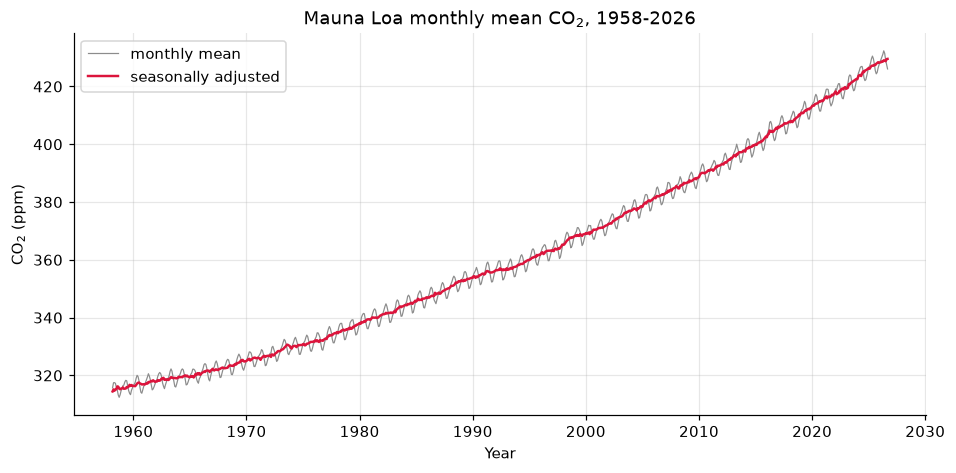

In [34]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(co2['date'], co2['average'], lw=0.8, color='0.55', label='monthly mean')
ax.plot(co2['date'], co2['deseasonalized'], lw=1.6, color='crimson', label='seasonally adjusted')
ax.set_xlabel('Year')
ax.set_ylabel('CO$_2$ (ppm)')
ax.set_title('Mauna Loa monthly mean CO$_2$, 1958-2026')
ax.legend()

4.3 [5 pt] Five statistical checks.


In [35]:
x = co2['year'] + (co2['month'] - 0.5) / 12
y = co2['average'].values
y_ds = co2['deseasonalized'].values

# check 1: linear trend over the whole record
slope, intercept = np.polyfit(x, y_ds, 1)
r = np.corrcoef(x, y_ds)[0, 1]
print(f'1) linear trend        : {slope * 10:+.2f} ppm/decade  (R2 = {r ** 2:.3f})')

# check 2: seasonal cycle
monthly_clim = co2.groupby('month_of_year')['average'].mean()
print(f'2) seasonal amplitude  : {monthly_clim.max() - monthly_clim.min():.2f} ppm '
      f'(max in month {monthly_clim.idxmax()}, min in month {monthly_clim.idxmin()})')

# check 3: acceleration of the growth rate
early = co2[co2['year'] <= 1980]
late = co2[co2['year'] >= 2005]
s_early = np.polyfit(early['year'] + (early['month'] - 0.5) / 12, early['average'], 1)[0]
s_late = np.polyfit(late['year'] + (late['month'] - 0.5) / 12, late['average'], 1)[0]
print(f'3) growth rate         : {s_early * 10:.2f} ppm/decade (<=1980) vs {s_late * 10:.2f} ppm/decade (>=2005)')

# check 4: autocorrelation of the monthly series
print(f'4) lag-1 autocorrelation: {np.corrcoef(y[:-1], y[1:])[0, 1]:.3f} '
      f'(deseasonalised: {np.corrcoef(y_ds[:-1], y_ds[1:])[0, 1]:.3f})')

# check 5: distribution and extremes
print(f'5) mean {y.mean():.1f} ppm, std {y.std():.1f} ppm, skewness {pd.Series(y).skew():.2f}, '
      f'range {y.min():.1f} - {y.max():.1f} ppm')

1) linear trend        : +16.71 ppm/decade  (R2 = 0.979)
2) seasonal amplitude  : 6.58 ppm (max in month 5, min in month 10)
3) growth rate         : 10.35 ppm/decade (<=1980) vs 23.73 ppm/decade (>=2005)
4) lag-1 autocorrelation: 0.999 (deseasonalised: 1.000)
5) mean 361.4 ppm, std 33.5 ppm, skewness 0.38, range 312.4 - 432.3 ppm


In [36]:
resid = y_ds - (slope * x + intercept)
print(f'residuals of the linear fit: std {resid.std():.2f} ppm, max |residual| {np.abs(resid).max():.2f} ppm')
big = co2.assign(resid=resid).reindex(pd.Series(resid).abs().sort_values().index[-5:])
print(big[['year', 'month', 'average', 'resid']].to_string(index=False))

residuals of the linear fit: std 4.80 ppm, max |residual| 11.32 ppm
 year  month  average     resid
 2026      8   427.55 10.951316
 2025     10   424.87 10.983923
 1958      9   313.21 11.078808
 2025     11   426.46 11.124663
 1958      8   314.93 11.318069
